# BÀI LAB 2: XỬ LÝ ẢNH SỐ - TOÁN TỬ ĐIỂM ẢNH VÀ CÁC BỘ LỌC KHÔNG GIAN

I> Toán Tử Điểm Ảnh
1. Thay đổi độ sáng: Tăng hoặc giảm độ sáng của toàn bộ hình ảnh bằng cách cộng hoặc trừ một giá trị cố định cho mỗi điểm ảnh.
2. Thay đổi độ tương phản: Tăng hoặc giảm độ tương phản bằng cách nhân mỗi điểm ảnh với một hằng số.
3. Biến đổi âm bản: Đảo ngược các giá trị điểm ảnh, tạo ra ảnh âm bản.
4. Cắt ngưỡng: Tạo ảnh nhị phân bằng cách so sánh giá trị mỗi điểm ảnh với một ngưỡng nhất định.


II> Lọc Tuyến Tính
1. Lọc trung bình: Làm mờ ảnh bằng cách tính giá trị trung bình của các điểm ảnh trong một vùng lân cận.
2. Lọc Gaussian: Làm mờ ảnh một cách tự nhiên hơn bằng cách sử dụng kernel Gaussian.
3. Làm sắc nét: Tăng cường các cạnh trong ảnh bằng cách sử dụng các kernel thích hợp.


III> Bài tập nâng cao
1. Phát hiện cạnh: Sử dụng các kernel Sobel, Prewitt để phát hiện các cạnh trong ảnh. 
2. Tự thiết kế kernel: Tạo các kernel tùy chỉnh để đạt được các hiệu ứng khác nhau.
3. So sánh các loại lọc: So sánh hiệu quả của các loại lọc khác nhau trên cùng một hình ảnh.
4. Áp dụng lọc phi tuyến tính: Tìm hiểu về các loại lọc không tuyến tính như median filter, bilateral filter.
---
## import library và hàm render ảnh


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Nhập đường dẫn từ bàn phím
path = input("Nhập đường dẫn tới file của bạn: ").strip()


print(f"Đường dẫn bạn vừa nhập: {path}")

imgRGB = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
imgGray = cv2.cvtColor(imgRGB, cv2.COLOR_RGB2GRAY)

def displayIMG(titles_list, images_list, w = 10, h = 6, histogram = False, forceGray = False):
    """
    Hàm hiển thị danh sách nhiều ảnh cạnh nhau một cách linh hoạt.
    
    Args:
        titles (list): Danh sách tiêu đề cho từng ảnh.
        images (list): Danh sách các mảng numpy chứa dữ liệu ảnh.
        w (int): Chiều rộng khung hình chung.
        h (int): Chiều cao khung hình chung.
        histogram (bool): Hiển thị thêm histogram (nếu cần).
        force_gray (bool): Buộc hiển thị tất cả dưới dạng ảnh xám (nếu cần thiết).
    """
    colum = len(images_list)
    # Chặn và cảnh báo 2 trường hợp đầu vào rỗng và số lượng ảnh và title không khớp nhau 
    if colum == 0:
        print("Không có hình ảnh đầu vào!")
        return
    elif len(titles_list) != colum:
        print("Số lượng title và ảnh không khớp nhau!")
        return
    
    row = 2 if histogram else 1
    fig, axes = plt.subplots(row, colum, figsize=(w, h), squeeze=False)
    colors = ('r', 'g', 'b') # Định nghĩa màu vẽ histogram theo chuẩn ảnh RGB của plt

    for i in range(colum):
        current_img = images_list[i]
        # Xử lý None trong list
        if current_img is None:
            # Xử lý khi gặp None: Hiển thị khung trống kèm thông báo lỗi
            axes[0, i].text(0.5, 0.5, "Lỗi: đọc lại vui lòng đọc lại [Cảnh báo]", 
                            color='red', fontsize=10, ha='center', va='center', 
                            transform=axes[0, i].transAxes)
            axes[0, i].set_title(titles_list[i], fontsize=12, fontweight='bold')
            axes[0, i].axis("off")
            
            # Nếu có hàng histogram ở dưới, cũng tắt luôn để tránh lỗi vẽ
            if histogram:
                axes[1, i].text(0.5, 0.5, "N/A", color='gray', fontsize=10, ha='center', va='center', transform=axes[1, i].transAxes)
                axes[1, i].axis("off")
            continue # Chuyển sang cột tiếp theo
        # --- HÀNG 1: HIỂN THỊ ẢNH ---
        if forceGray:
            # hiển thị ảnh xám
            axes[0, i].imshow(current_img, cmap="gray")
        else:
            # hiển thị ảnh màu 3 kênh RGB tự động hiển thị chuẩn
            axes[0, i].imshow(current_img)
        axes[0, i].set_title(titles_list[i], fontsize=12, fontweight='bold')
        axes[0, i].axis("off")

        if histogram:
            # --- HÀNG 2: HIỂN THỊ HISTOGRAM TƯƠNG ỨNG ---
            # Tách các kênh màu của ảnh hiện tại để vẽ histogram
            if forceGray:
                hist = cv2.calcHist([current_img], [0], None, [256], [0, 256])
                axes[1, i].plot(hist, color="gray", alpha=0.8)
            else:
                for c, col in enumerate(colors):
                    # Tính toán histogram cho từng kênh màu R, G, B
                    hist = cv2.calcHist([current_img], [c], None, [256], [0, 256])
                    axes[1, i].plot(hist, color=col, alpha=0.8)
                
            axes[1, i].set_xlim([0, 256])
            axes[1, i].grid(True, linestyle='--', alpha=0.5)
            
            # Gắn nhãn cho trục của cột đầu tiên cho gọn đồ thị
            if i == 0:
                axes[1, i].set_ylabel("Tần suất (Số lượng)")
            axes[1, i].set_xlabel("Giá trị Pixel")
            axes[1, i].set_title(f"Histogram {titles_list[i]}", fontsize=10)

    plt.tight_layout()
    plt.show()




Đường dẫn bạn vừa nhập: C:\Users\TAN LOC\Desktop\CV_Lab-1-5-\Lab2\images.jpg


## I. TOÁN TỬ ĐIỂM ẢNH (POINT OPERATORS)
Toán tử điểm ảnh là phép biến đổi giá trị của mỗi điểm ảnh (pixel) độc lập với các điểm ảnh lân cận, dựa trên một hàm toán học tuyến tính

## 1.2. Tăng giảm độ sáng độ tương phản
- **Độ sáng**: cộng hoặc trừ một giá trị cố định cho mỗi điểm ảnh.
- **Độ tương phản**: nhân mỗi điểm ảnh với một hằng số.

### Dùng để
- **Tiền xử lý ảnh (Image Preprocessing):** Khắc phục các vấn đề về điều kiện ánh sáng kém (ảnh quá tối do thiếu sáng hoặc quá lóa do thừa sáng) trước khi đưa vào các thuật toán thị giác máy tính (Computer Vision) phức tạp hơn như nhận diện khuôn mặt hay phát hiện biên.
- **Tăng cường chất lượng hiển thị:** Giúp làm nổi bật các chi tiết bị ẩn trong vùng tối hoặc làm dịu các vùng quá sáng để con người dễ quan sát hơn.

### Cách dùng 
- **Kỹ thuật Vector hóa (Vectorization):** Thay vì dùng vòng lặp `for` lồng nhau để duyệt từng pixel (gây chậm hiệu năng trong Python), ta áp dụng phép toán ma trận trực tiếp qua thư viện **NumPy**.
- **Chống tràn dữ liệu (Clipping):** 
  - Do kiểu dữ liệu chuẩn của ảnh là `uint8` ($[0, 255]$), việc nhân hoặc cộng trực tiếp rất dễ gây ra hiện tượng tràn số (Overflow/Underflow).
  - Ta giải quyết bằng cách ép kiểu sang `np.float32` để tính toán chính xác, sau đó sử dụng hàm **`np.clip(result, 0, 255)`** để kẹp các giá trị vượt ngưỡng về đúng biên an toàn $[0, 255]$ trước khi ép lại về `uint8`.

### Kết quả:
- **Tác động trên Histogram:**
  - **Độ sáng ($\beta$):** Khi tăng độ sáng ($\beta > 0$), biểu đồ Histogram dịch chuyển về phía ngưỡng tối đa ($255$). Ngược lại, giảm độ sáng dịch chuyển histogram về phía $0$.
  - **Độ tương phản ($\alpha$):** Khi tăng độ tương phản ($\alpha > 1$), dải phân bố của histogram bị giãn rộng, giúp phân tách rõ vùng sáng và vùng tối. Khi giảm độ tương phản ($\alpha < 1$), histogram bị co cụm lại, khiến ảnh trở nên mờ nhạt.

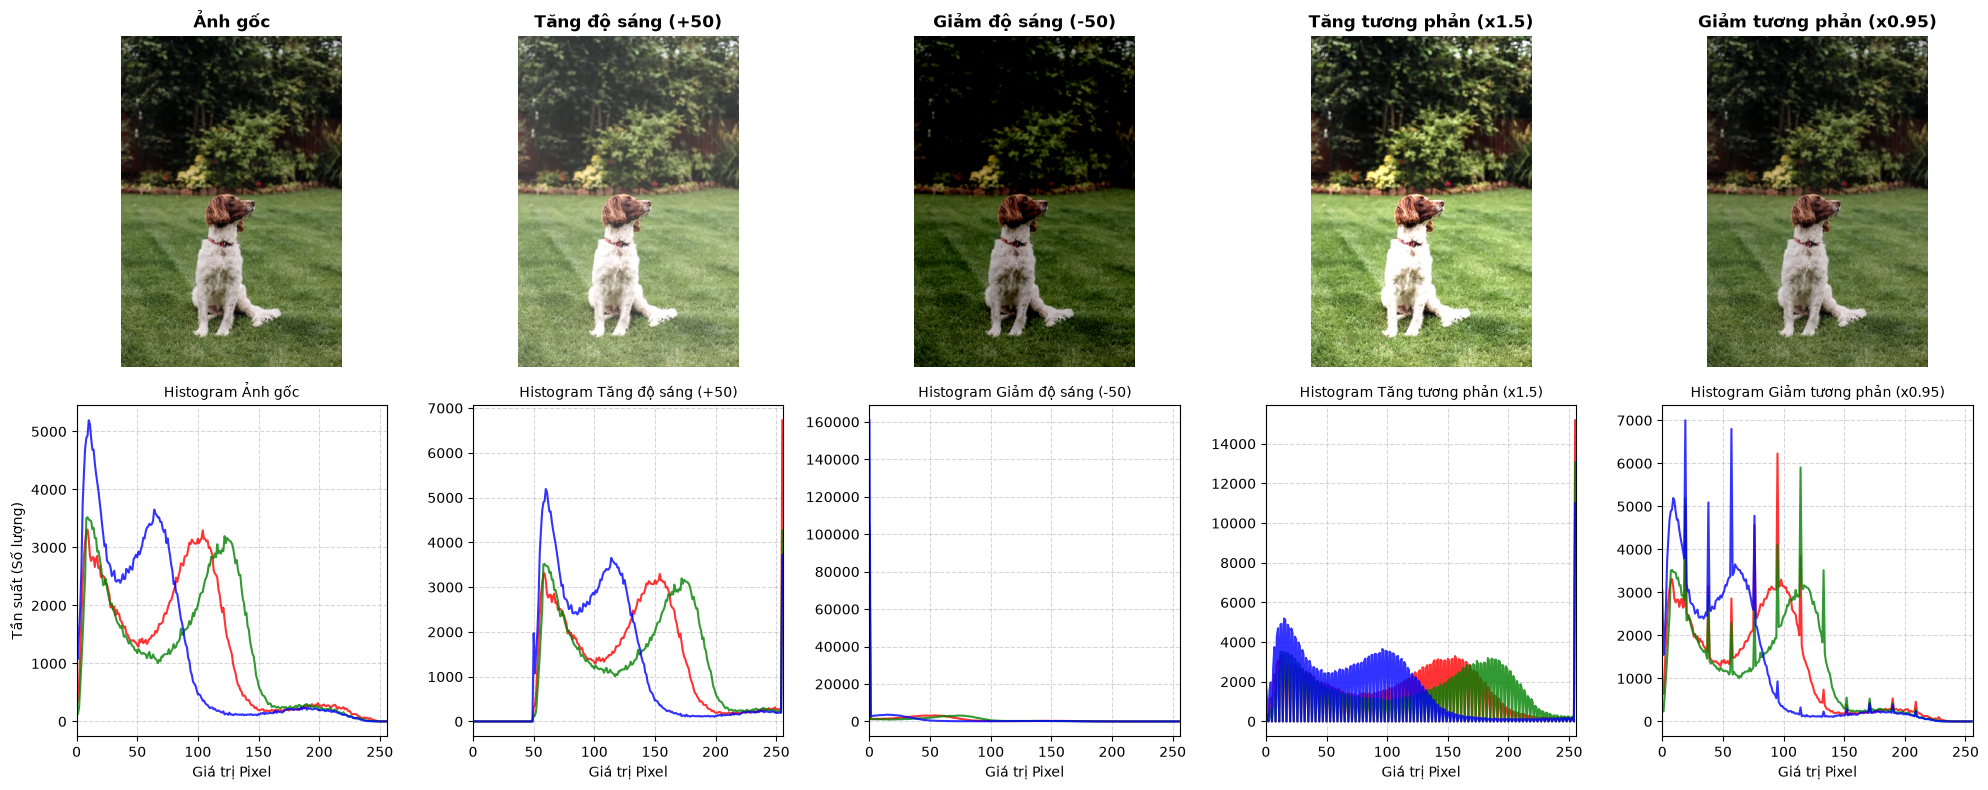

In [2]:
def lightAndContrast(img, light=0, contrast=1.0):
  """
  Điều chỉnh độ sáng và độ tương phản của ảnh sử dụng phép toán vector hóa.
  
  Args:
      img (np.ndarray): Ảnh đầu vào (có thể là ảnh xám 2D hoặc ảnh màu RGB/BGR 3D).
      light (int/float): Giá trị cộng thêm để thay đổi độ sáng (-255 đến 255).
      contrast (float): Hệ số nhân để thay đổi độ tương phản (> 0).
      
  Returns:
      np.ndarray: Ảnh sau khi biến đổi (kiểu uint8).
  """
  # Chuyển sang float32 để tránh tràn số khi nhân/cộng, sau đó áp dụng biến đổi tuyến tính
  img_processed = contrast * img.astype(np.float32) + light
  
  # Giới hạn giá trị trong khoảng [0, 255] để mô phỏng chính xác dải màu uint8
  result = np.clip(img_processed, 0, 255)
  
  return result.astype(np.uint8)

# Tạo danh sách 5 ảnh xử lý
images_list = [
    imgRGB,                                       # 0. Ảnh gốc
    lightAndContrast(imgRGB, light=50),           # 1. Tăng độ sáng
    lightAndContrast(imgRGB, light=-50),          # 2. Giảm độ sáng
    lightAndContrast(imgRGB, contrast=1.5),       # 3. Tăng độ tương phản
    lightAndContrast(imgRGB, contrast=0.95)       # 4. Giảm độ tương phản
]

titles_list = [
    "Ảnh gốc",
    "Tăng độ sáng (+50)",
    "Giảm độ sáng (-50)",
    "Tăng tương phản (x1.5)",
    "Giảm tương phản (x0.95)"
]

displayIMG(titles_list, images_list, 20, 8, True)



## 3. Biến đổi âm bản
- Đảo ngược hoàn toàn các giá trị cường độ sáng của từng pixel trong hình ảnh. Pixel nào có giá trị lớn (sáng/gần 255) sẽ bị kéo xuống giá trị nhỏ (tối/gần 0), và ngược lại. Điểm có giá trị trung bình (ví dụ 128) sẽ giữ nguyên hoặc dịch chuyển tương ứng.
### Dùng để
- Làm nổi bật chi tiết ẩn trong vùng tối: Khi một bức ảnh có quá nhiều vùng tối lấn át khiến các chi tiết nhỏ bên trong đó bị che khuất, việc đảo ngược sang âm bản sẽ biến các vùng tối thành sáng, giúp mắt người hoặc thuật toán dễ dàng quan sát và phân tích hơn.
### Cách dùng
- Nhờ tính chất tuyến tính đơn giản và cơ chế vector hóa của thư viện NumPy, thực hiện một phép trừ mảng trực tiếp


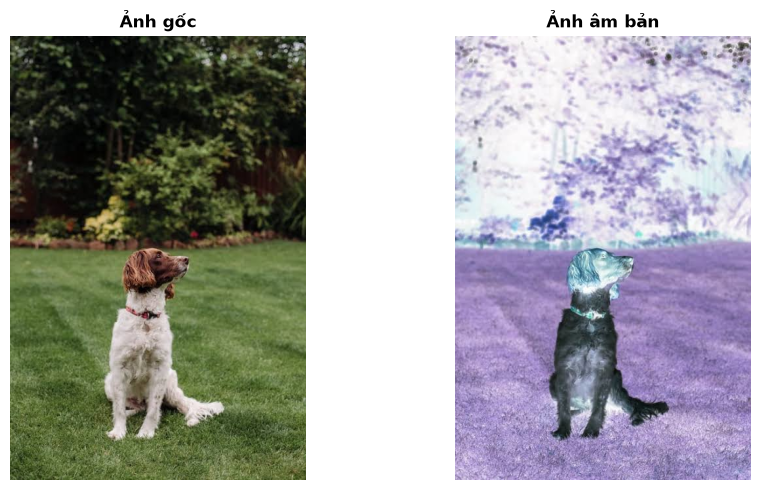

In [4]:
def imgNative(img):
    """
    Thực hiện biến đổi âm bản cho ảnh xám hoặc ảnh màu.
        s = 255 - r
    Trong đó:
        r: Giá trị cường độ sáng của pixel ở ảnh gốc.
        s: Giá trị cường độ sáng của pixel sau khi biến đổi.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (có thể là ảnh xám 2D hoặc ảnh màu RGB/BGR 3D).
        
    Returns:
        np.ndarray: Ảnh âm bản sau khi đảo ngược giá trị pixel (kiểu uint8).
    """
    # Lấy 255 trừ đi ma trận ảnh gốc
    return 255-img

images_list = [
    imgRGB,
    imgNative(imgRGB)
]
titles_list = [
    "Ảnh gốc",
    "Ảnh âm bản"
]
displayIMG(titles_list, images_list, 10, 5)

## 4. Cắt ngưỡng
- Chuyển đổi ảnh xám (Grayscale) hoặc ảnh màu thành ảnh nhị phân (Binary Image) – ảnh chỉ chứa đúng 2 giá trị màu: Đen ($0$) và Trắng ($255$).
### Dùng để
- Giúp loại bỏ hoàn toàn các thông tin nhiễu, màu sắc phức tạp hoặc độ sáng thay đổi không cần thiết, chỉ giữ lại hình thù/khung của đối tượng cần phân tích.
- Giảm dung lượng và độ phức tạp dữ liệu.
### Cách dùng
- Nhờ tính chất mảng của NumPy, ta có thể hiện thực hóa việc cắt ngưỡng một cách cực kỳ nhanh chóng bằng pháp toán gán điều kiện mảng (Boolean Indexing)

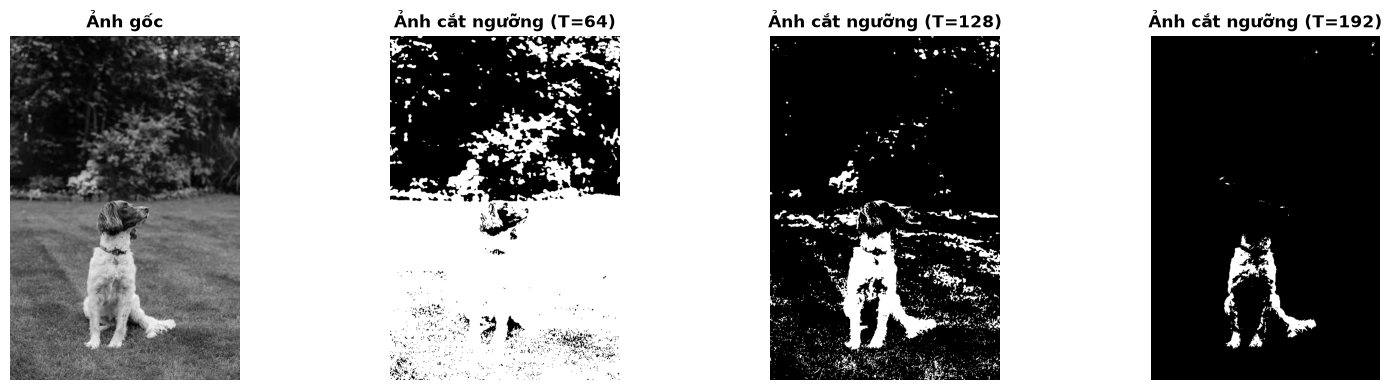

In [8]:
def imgBinary(img, threshold=128):
    """
    Thực hiện cắt ngưỡng nhị phân hóa (Binary Thresholding) trên ảnh xám.
    
    Lý do cần đầu vào Grayscale:
        Phép cắt ngưỡng chỉ dựa trên một chiều cường độ sáng (intensity) duy nhất. 
        Nếu dùng ảnh màu 3 kênh (RGB), việc cắt ngưỡng độc lập trên từng kênh sẽ 
        làm biến dạng màu sắc và không tạo ra ảnh nhị phân đen/trắng thuần túy.
    
    Args:
        imgGray (np.ndarray): Ảnh đầu vào (Bắt buộc phải là ảnh xám 2D - Grayscale).
        threshold (int): Giá trị ngưỡng phân chia, từ 0 đến 255 (mặc định là 128).
        
    Returns:
        np.ndarray: Ảnh nhị phân kết quả, chỉ chứa đúng 2 giá trị 0 (Đen) và 255 (Trắng).
    """
    if len(img.shape) != 2:
        print("[Cảnh báo] Đầu vào ảnh nên là kênh màu Grayscale vì kênh màu khác có thể làm biến đổi màu sắc và không phù hợp với mục đích ảnh nhị phân!")
        return None
    elif threshold <= 0 or threshold >= 255:
        print("Giá trị cắt ngưỡng cần nằm trong [0,255] để được ảnh nhị phân")
    # Tạo bản sao để tránh làm thay đổi ảnh gốc
    img_binary = img.copy()
    
    # Các pixel nhỏ hơn ngưỡng chuyển thành 0 (Đen)
    img_binary[img_binary < threshold] = 0
    
    # Các pixel lớn hơn hoặc bằng ngưỡng chuyển thành 255 (Trắng)
    img_binary[img_binary >= threshold] = 255
    
    return img_binary

titles_list = [
    "Ảnh gốc",
    "Ảnh cắt ngưỡng (T=64)",
    "Ảnh cắt ngưỡng (T=128)",
    "Ảnh cắt ngưỡng (T=192)"
]
images_list = [
    imgGray,
    imgBinary(imgGray, threshold=64),
    imgBinary(imgGray),
    imgBinary(imgGray, threshold=192)
]

displayIMG(titles_list, images_list, 16, 4, forceGray=True)

## II> Lọc Tuyến Tính
## 1. Lọc trung bình
- Tại mỗi vị trí pixel, giá trị mới của pixel đó sẽ được tính bằng trung bình cộng tất cả các giá trị pixel nằm bên trong cửa sổ Kernel. Mỗi hệ số trong kernel đều bằng nhau ($\frac{1}{width \times height}$), nghĩa là mọi pixel lân cận đều đóng góp một trọng số như nhau vào kết quả cuối cùng.
### Dùng để
- Làm mờ ảnh: Giúp làm dịu các chi tiết quá sắc nét hoặc làm giảm sự đột ngột về cường độ sáng giữa các pixel cạnh nhau.
- Khử nhiễu cơ bản: Hiệu quả trong việc xóa bỏ các loại nhiễu phân bố nhẹ (như nhiễu Gaussian cường độ thấp) bằng cách "san phẳng" các giá trị pixel bị lệch đột ngột so với vùng xung quanh.
- Hạn chế: Vì lấy trung bình cộng nên nó sẽ làm mờ các cạnh (edges) của vật thể trong ảnh, khiến ảnh trở nên kém sắc nét nếu dùng kernel quá lớn.
### Cách dùng
- src (source): Ảnh đầu vào cần lọc (có thể là ảnh xám 2D hoặc ảnh màu 3D).

- ksize (kernel size): Kích thước của bộ lọc, truyền vào dưới dạng một tuple (width, height) (ví dụ: (5, 5) hoặc (3, 3)). Kích thước này bắt buộc phải là các số nguyên dương lẻ (odd numbers) để tâm của kernel nằm chính xác tại một pixel.

    - Lưu ý: Kernel càng lớn (ví dụ (9,9)), ảnh càng mờ nhòe nhiều hơn.

- anchor (tùy chọn): Vị trí tâm của kernel. Mặc định để giá trị (-1, -1) nghĩa là tâm sẽ tự động nằm ở chính giữa kernel.

-borderType (tùy chọn): Cách xử lý các pixel nằm ở đường biên của bức ảnh (khi kernel tràn ra ngoài kích thước ảnh). Mặc định thường dùng cv2.BORDER_DEFAULT (phản chiếu gương qua biên).

Kích thước kernel cần lẻ để tránh hiện tượng dịch chuyển chiều không gian sau khi lọc!


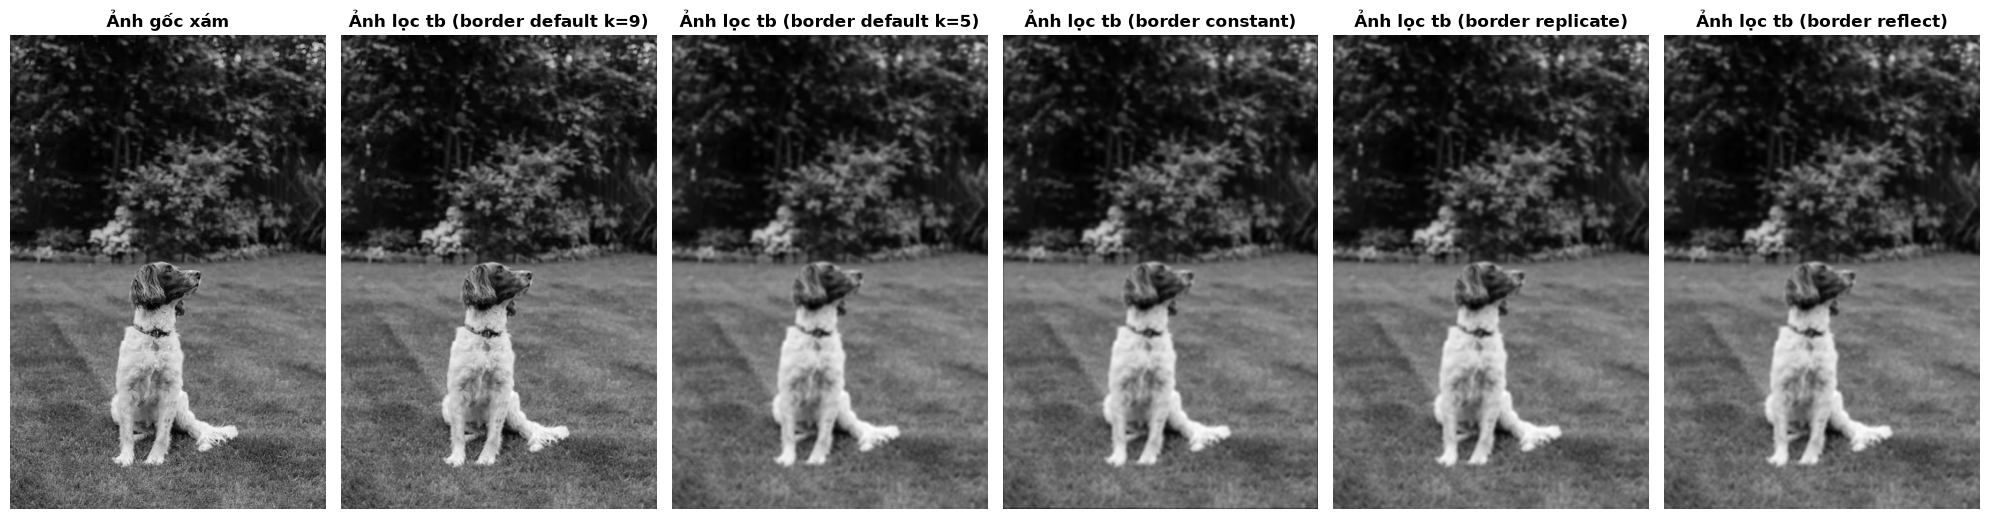

In [ ]:
def filterMean(img, k, border = cv2.BORDER_DEFAULT):
  """
 Thực hiện lọc trung bình (Mean Filter) để làm mờ và khử nhiễu.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (ảnh xám hoặc ảnh màu).
        k: kích thước kernel
        border: cách xử lý pixel biên của ảnh
        
    Returns:
        np.ndarray: Ảnh sau khi được làm mờ qua bộ lọc trung bình kích thước k.
  """
  # Kiểm tra k <=0 vì kích thước 1 kernel không <=0
  if k <= 0:
    print("[Cảnh báo] kích thước cần > 0!")
    return None 
  # Tránh hiện tượng dịch chuyển không gian với k chẵn
  elif k%2 == 0:
    print("Kích thước kernel k phải là số nguyên dương lớn hơn 0.")
  return cv2.blur(img, (k,k), borderType = border)

images_list = [
  imgGray,
  filterMean(imgGray, 2, cv2.BORDER_DEFAULT),
  filterMean(imgGray, 5, cv2.BORDER_DEFAULT),
  filterMean(imgGray, 5, cv2.BORDER_CONSTANT),
  filterMean(imgGray, 5, cv2.BORDER_REPLICATE),
  filterMean(imgGray, 5, cv2.BORDER_REFLECT)
]

titles_list = [
  "Ảnh gốc xám",
  "Ảnh lọc tb (border default k=9)",
  "Ảnh lọc tb (border default k=5)",
  "Ảnh lọc tb (border constant)",
  "Ảnh lọc tb (border replicate)",
  "Ảnh lọc tb (border reflect)"
]

displayIMG(titles_list, images_list, 20, 8, forceGray=True)

## 2. Lọc gaussian
- Bộ lọc Gaussian sử dụng một hàm phân phối chuẩn (Gaussian distribution / hình chuông) để tính toán trọng số.Bản chất toán học:Các pixel nằm gần tâm của kernel sẽ có trọng số lớn nhất (đóng góp nhiều nhất vào giá trị mới).Các pixel càng ở xa tâm thì trọng số càng giảm dần theo hàm số mũ.
-Công thức hàm Gaussian 2 chiều:

$$G(x, y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2 + y^2}{2\sigma^2}}$$


- Trong đó: $\sigma$ (sigma) là độ lệch chuẩn, quyết định độ rộng của "chuông" Gaussian (độ lan tỏa của sự mờ).
### Dùng để
- Khử nhiễu tự nhiên (Natural Noise Reduction): Loại bỏ rất tốt các loại nhiễu phân bố ngẫu nhiên (như nhiễu cảm biến, nhiễu ánh sáng yếu).
- Bảo toàn cạnh tốt hơn lọc trung bình: Vì các pixel ở xa tâm đóng góp trọng số rất nhỏ, bộ lọc Gaussian ít làm nhòe sắc nét các biên (edges) của vật thể hơn so với lọc trung bình (Mean Filter).
### Cách dùng
    cv2.GaussianBlur(src, ksize, sigmaX, sigmaY, borderType)
- src: Ảnh đầu vào cần lọc.
- ksize: Kích thước kernel (ví dụ: (5, 5) hoặc (3, 3)). Bắt buộc phải là số nguyên dương lẻ. 
    - Lưu ý: Nếu truyền vào (0, 0), OpenCV sẽ tự động tính toán kích thước kernel dựa vào giá trị của sigmaX theo công thức: $$k = 2 \times \text{round}(3\sigma) + 1$$
- sigmaX: Độ lệch chuẩn theo trục hoành $X$. Nếu để 0, hệ thống sẽ tự tính toán dựa theo kích thước kernel. sigmaX càng lớn thì ảnh càng mờ nhòe mạnh.
- sigmaY: Độ lệch chuẩn theo trục tung $Y$. Nếu để 0, nó sẽ tự động lấy giá trị bằng với sigmaX (giúp phân phối đối xứng).
- borderType: Phương pháp xử lý biên (tương tự như cv2.blur).

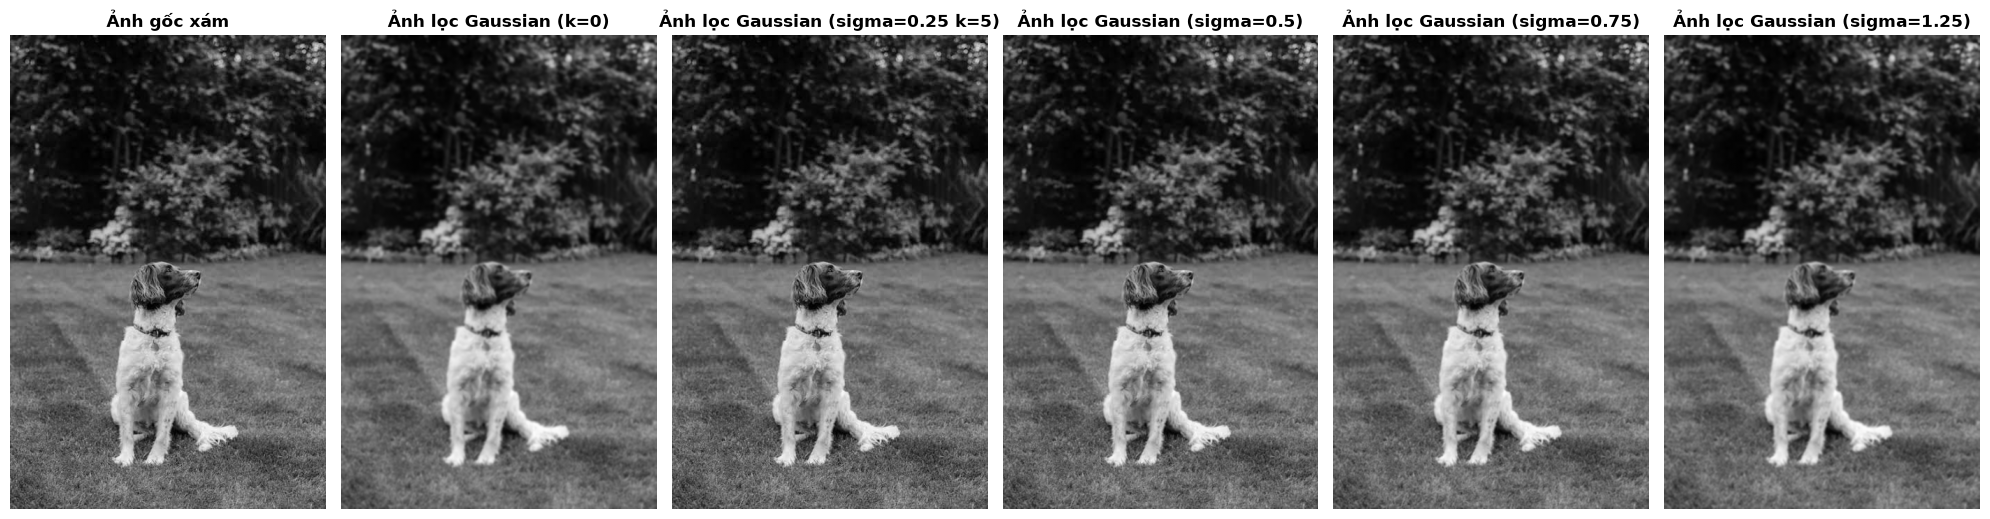

In [ ]:
def filterGaussian(img, k, sigma, border = cv2.BORDER_DEFAULT):
  """
    Thực hiện lọc Gaussian để làm mờ và khử nhiễu tự nhiên.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (ảnh xám hoặc ảnh màu).
        k (int): Kích thước kernel (khuyến nghị số lẻ, vd: 3, 5, 7).
        sigma (float): Độ lệch chuẩn của phân phối Gaussian.
        
    Returns:
        np.ndarray: Ảnh sau khi qua bộ lọc Gaussian.
  """
  # chỉ kiểm tra chẵn lẻ mà không cần kiểm tra <=0 vì trong cv2.GaussianBlur có k=0 để tự động tính k theo sigma phù hợp và các giá trị âm sẽ được đưa về
  if k != 0:
    if k%2==0:
      print("[Cảnh báo] Kích thước kernel cần lẻ và lớn hơn 0!")
      return None
  
  return cv2.GaussianBlur(img, (k,k), sigma, borderType = border)

images_list = [
  imgGray,
  filterGaussian(imgGray, 0, 1.25),
  filterGaussian(imgGray, 5, 0.25),
  filterGaussian(imgGray, 5, 0.5),
  filterGaussian(imgGray, 5, 0.75),
  filterGaussian(imgGray, 5, 1.25)
]

titles_list = [
  "Ảnh gốc xám",
  "Ảnh lọc Gaussian (k=0)",
  "Ảnh lọc Gaussian (sigma=0.25 k=5)",
  "Ảnh lọc Gaussian (sigma=0.5)",
  "Ảnh lọc Gaussian (sigma=0.75)",
  "Ảnh lọc Gaussian (sigma=1.25)"
]

displayIMG(titles_list, images_list, 20, 8, forceGray=True)

## 3. Làm sắc nét
- Tăng cường các thành phần tần số cao trong không gian ảnh, nhằm làm nổi bật các cạnh đường biên, ranh giới giữa các vùng có sự thay đổi đột ngột về cường độ sáng, và các chi tiết nhỏ bị mờ.
- Khác với bộ lọc làm mờ (có tổng các hệ số chia đều hoặc giảm dần từ tâm), bộ lọc làm nét sử dụng một mặt nạ (kernel) có trọng số trung tâm rất lớn mang dấu dương, vây quanh bởi các trọng số âm ở các pixel lân cận sao cho tổng các phần tử trong kernel bằng $1$ (hoặc $0$ tùy loại).

### Dùng để
- Khắc phục hiện tượng mờ nhòe: Khôi phục lại độ chi tiết cho các bức ảnh bị mờ do rung tay, lấy nét kém, hoặc do hậu quả của việc qua các bộ lọc làm mờ không gian trước đó.

- Làm nổi bật cấu trúc và văn bản
### Cách dùng
- src: Ảnh đầu vào cần lọc (ảnh xám hoặc ảnh màu).

- ddepth: Độ sâu của ảnh đầu ra (Data depth, ví dụ: CV_8U, CV_32F). Nếu truyền vào giá trị -1, ảnh đầu ra sẽ giữ nguyên kiểu dữ liệu (bit-depth) giống hệt với ảnh đầu vào.

- kernel: Ma trận NumPy (np.array) chứa các trọng số do ta tự thiết kế (kiểu np.float32).

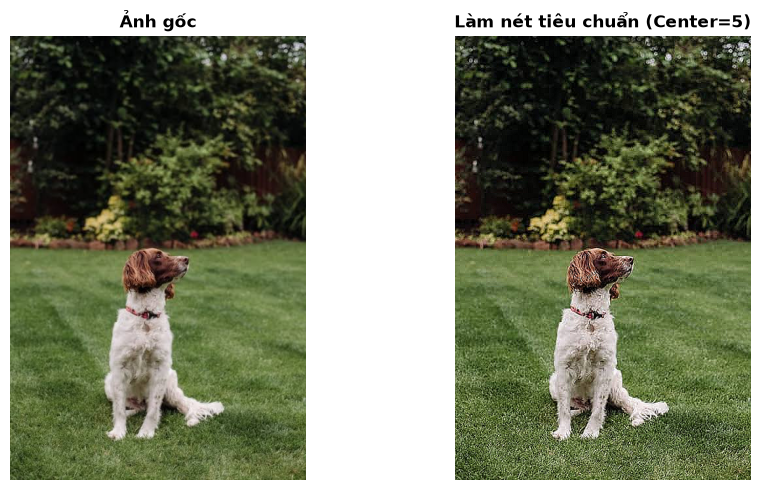

In [18]:
def filterSharpen(img, kernel=None):
    """
    Thực hiện làm nét ảnh bằng cách tự thiết kế Custom Kernel.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (ảnh xám hoặc ảnh màu).
        kernel (np.ndarray, optional): Ma trận kernel tùy chỉnh dùng để làm nét. 
                                       Mặc định là None (sẽ tự động dùng kernel chuẩn 3x3 với trọng số làm nét tiêu chuẩn).
    Returns:
        np.ndarray: Ảnh sau khi được làm sắc nét.
    """
    if kernel is None:
        kernel = np.array([
            [0,-1,0],
            [-1,5,-1],
            [0,-1,0]
        ], dtype = np.float32)
    else:

        # KIỂM TRA TÍNH HỢP LỆ (INPUT VALIDATION)
        # Kiểm tra xem kernel có phải là mảng NumPy không
        if not isinstance(kernel, np.ndarray):
            print("[Cảnh báo] Kernel phải là một đối tượng numpy.ndarray!")
            return None

        # Kiểm tra số chiều (phải là ma trận 2D)
        if kernel.ndim != 2:
            print(f"[Cảnh báo] Kernel phải có 2 chiều (ndim=2), hiện tại là {kernel.ndim} chiều.")
            return None

        # Kiểm tra kích thước hàng và cột có phải là số lẻ không
        rows, cols = kernel.shape
        if rows % 2 == 0 or cols % 2 == 0:
            print(f"[Cảnh báo] Kích thước kernel phải là số lẻ (ví dụ 3x3, 5x5), hiện tại là {rows}x{cols}.")
            return None

        # Kiểm tra tổng các phần tử (Khuyến nghị tổng bằng 1.0 để bảo toàn độ sáng tổng thể của ảnh)
        kernel_sum = np.sum(kernel)
        if not np.isclose(kernel_sum, 1.0, atol=1e-5):
            print(f"[Cảnh báo] Tổng các phần tử của kernel hiện tại bằng {kernel_sum:.2f} (Khuyến nghị bằng 1.0 để giữ nguyên độ sáng ảnh).")
            return None

    # thực thi
    return cv2.filter2D(img, -1, kernel)


images_list = [
    imgRGB,
    filterSharpen(imgRGB)
]

titles_list = [
    "Ảnh gốc",
    "Làm nét tiêu chuẩn (Center=5)"
]

displayIMG(titles_list, images_list, 10, 5)

## III> Bài tập nâng cao
## 1. Phát hiện cạnh Sobel và Prewitt
- Sobel và Prewitt đều là các toán tử phát hiện biên dựa trên đạo hàm bậc nhất.
- Hoạt động dựa trên việc trượt các mặt nạ (kernel) kích thước $3 \times 3$ qua ảnh để xấp xỉ tốc độ biến thiên cường độ sáng (đạo hàm) theo hai hướng:
    - Theo chiều ngang ($G_x$): Phát hiện biên đứng (vertical edges).
    - Theo chiều dọc ($G_y$): Phát hiện biên ngang (horizontal edges).
    - Biên độ tổng hợp ($G$): Cường độ biên tại mỗi pixel được tính toán kết hợp từ hai thành phần đạo hàm:$$G = \vert{}G_x\vert{} + \vert{}G_y\vert{} \quad \text{hoặc} \quad G = \sqrt{G_x^2 + G_y^2}$$
## Dùng để 
- Trích xuất biên và phân đoạn đối tượng: Xác định ranh giới, hình dáng cấu trúc và các đường nét phân chia giữa các vùng khác nhau trong bức ảnh.

- Tiền xử lý tiêu chuẩn: Tạo nền tảng dữ liệu quan trọng cho các bài toán nhận diện hình dạng (Shape Recognition), theo dõi chuyển động (Motion Tracking) hoặc các thuật toán thị giác máy tính nâng cao.
## Phân biệt
- Prewitt: Do không có hệ số trọng số ưu tiên cho điểm trung tâm, Prewitt phản hồi nhạy cảm hơn với nhiễu ngẫu nhiên cục bộ, khiến các đường biên thu được thường có cảm giác thô (coarse) và đứt quãng hơn.
- Soble: Nhờ trọng số trung tâm lớn, Sobel vừa thực hiện tính đạo hàm vừa kết hợp làm mờ nhẹ cục bộ, giúp triệt tiêu nhiễu tốt hơn và mang lại các đường biên sắc nét, liền mạch và rõ ràng hơn so với Prewitt.


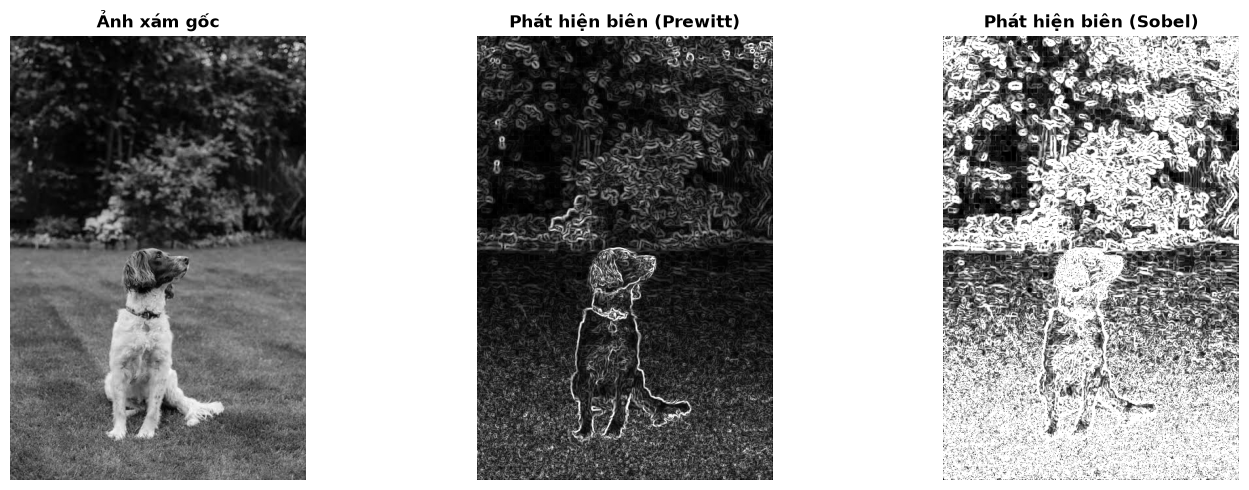

In [ ]:
def detectEdges(imgGray, method="sobel", ksize=3):
    """ 
    Phát hiện biên sử dụng toán tử Sobel hoặc Prewitt.
    
    Args:
        imgGray (np.ndarray): Ảnh đầu vào (bắt buộc là ảnh xám 2D).
        method (str): Phương pháp chọn ("sobel" hoặc "prewitt").
        ksize (int): Kích thước kernel (thường là 3).
        
    Returns:
        np.ndarray: Ảnh biên tổng hợp sau khi xử lý.
    """
    if imgGray.ndim != 2:
        print("[Cảnh báo] Đầu vào imgGray phải là ảnh xám 2D (Grayscale)!")
        return None
        
    method_lower = method.lower()
    if method_lower not in ["sobel", "prewitt"]:
        print(f"[Cảnh báo] Phương pháp '{method}' không hợp lệ! Chỉ hỗ trợ 'sobel' hoặc 'prewitt'.")
        return None
        
    # Kiểm tra ksize chung phải là số lẻ (hoặc -1 riêng cho Scharr)
    if ksize != -1 and (ksize <= 0 or ksize % 2 == 0):
        print(f"[Cảnh báo] Kích thước ksize = {ksize} không hợp lệ! Bắt buộc phải là số lẻ dương hoặc -1.")
        return None
    
    if method_lower == "sobel":
        # Sử dụng hàm tối ưu sẵn của OpenCV cho Sobel
        grad_x = cv2.Sobel(imgGray, cv2.CV_64F, 1, 0, ksize=-5)
        grad_y = cv2.Sobel(imgGray, cv2.CV_64F, 0, 1, ksize=-5)
        
    elif method_lower == "prewitt":
        # Tự thiết kế kernel Prewitt 3x3
        kernel_x = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
        kernel_y = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float32)
                             
        grad_x = cv2.filter2D(imgGray, cv2.CV_64F, kernel_x)
        grad_y = cv2.filter2D(imgGray, cv2.CV_64F, kernel_y)
   

    # Tính biên độ gradient tổng hợp (Magnitude)
    magnitude = cv2.magnitude(grad_x, grad_y)
    
    # Chuẩn hóa về kiểu uint8 để hiển thị hình ảnh chuẩn
    edge_image = cv2.convertScaleAbs(magnitude)
    
    return edge_image

# --- Khối thực thi và so sánh trực quan ---
images_list = [
    imgGray,
    detectEdges(imgGray, method="prewitt"),
    detectEdges(imgGray, method="sobel")
]

titles_list = [
    "Ảnh xám gốc",
    "Phát hiện biên (Prewitt)",
    "Phát hiện biên (Sobel)"
]

displayIMG(titles_list, images_list, 15, 5, forceGray=True)

## 2. Tự thiết kế kernel: Tạo các kernel tùy chỉnh để đạt được các hiệu ứng khác nhau.
-  Kernel (hay còn gọi là mặt nạ - mask, cửa sổ lọc) là một ma trận số thực có kích thước nhỏ (thường là $3 \times 3, 5 \times 5, 7 \times 7$), đóng vai trò là hàm trọng số trượt qua toàn bộ bức ảnh để thực hiện phép toán **tích chập (Convolution)** hoặc **tương quan chéo (Cross-correlation)**.
- **Vai trò:** Mọi phép lọc không gian (từ làm mờ, làm nét cho đến phát hiện biên) suy cho cùng đều được định nghĩa hoàn toàn bởi các con số nằm bên trong ma trận Kernel này.

###  Dùng để 
- Giúp kỹ sư chủ động can thiệp sâu vào mức độ xử lý ảnh thay vì bị gò bó bởi các hàm cố định có sẵn.
- Cho phép tạo ra các bộ lọc chuyên biệt tùy theo bài toán thực tế (ví dụ: chỉ lọc biên theo hướng chéo, làm nét mạnh, hoặc làm mờ chọn lọc vùng tần số thấp).

### Nguyên tắc vàng khi thiết kế Custom Kernel
Để tự thiết kế một kernel chạy đúng và không bị lỗi toán học, ta bắt buộc phải tuân thủ các nguyên tắc sau:
1. **Kích thước phải là số lẻ ($3 \times 3, 5 \times 5,...$):** Để đảm bảo luôn tồn tại một **pixel tâm (center pixel)** chính xác, giúp ảnh không bị lệch pha (spatial shift).
2. **Quy tắc tổng trọng số (Sum of Weights):**
   - **Tổng các phần tử bằng 1 ($\sum K = 1$):** Dùng cho các bộ lọc bảo toàn độ sáng như *Làm mờ (Blur)* hoặc *Làm nét (Sharpen)*. Giúp ảnh đầu ra không bị quá sáng lóa hoặc tối đen.
   - **Tổng các phần tử bằng 0 ($\sum K = 0$):** Dùng cho các bộ lọc đạo hàm / *Phát hiện biên (Edge Detection)*. Ở những vùng ảnh đồng màu (intensity không đổi), đạo hàm phải bằng 0.

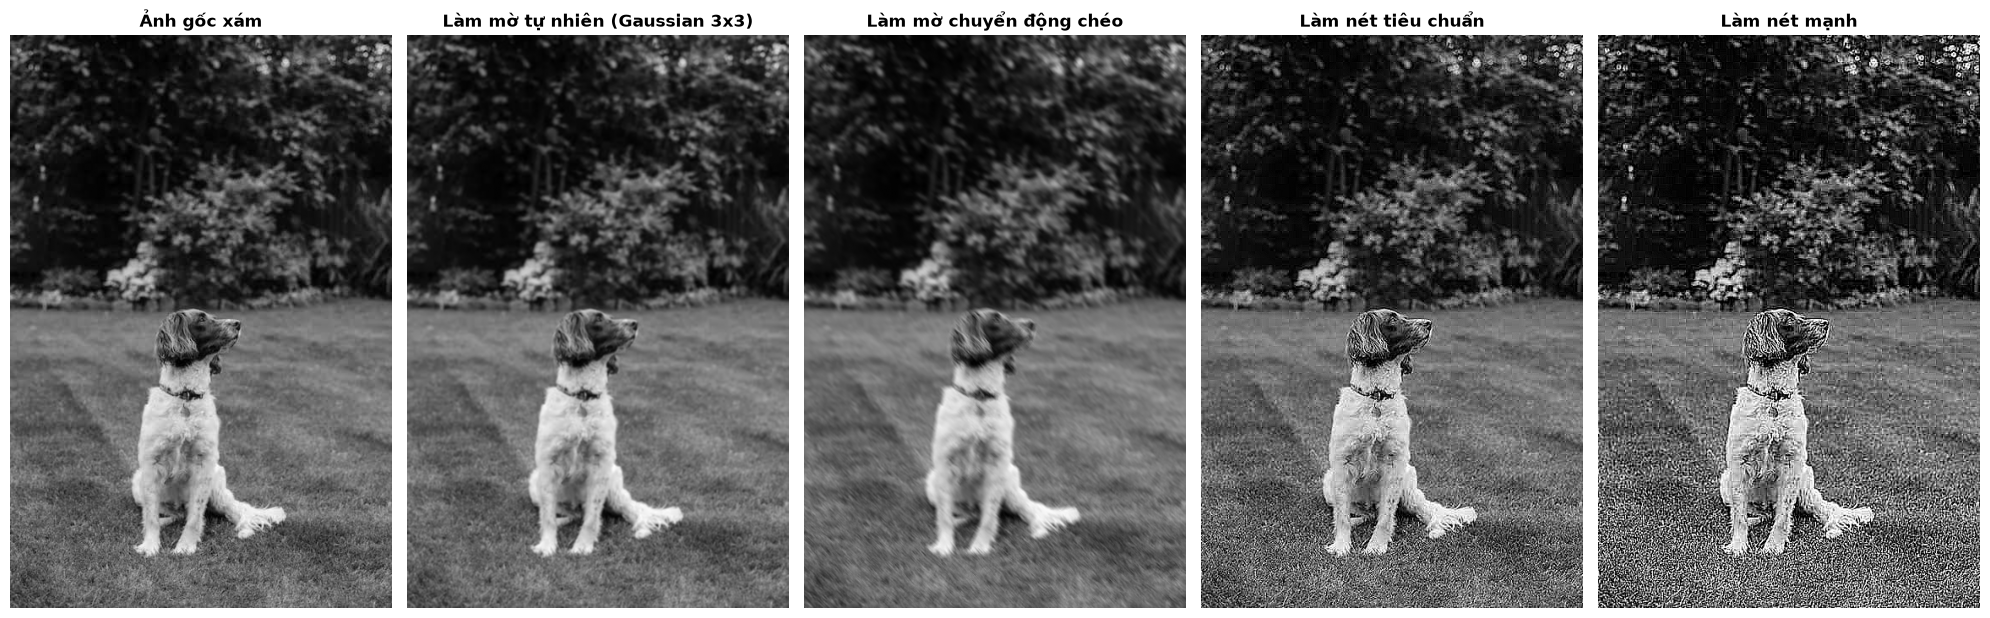

In [ ]:
def designKernelAndFilter(img):
    """
    Hàm thiết kế các Custom Kernel tùy chỉnh và trực quan hóa kết quả qua lưới 2x2.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (khuyến nghị ảnh xám 2D).
    """
    # 1. Kernel làm mờ tự nhiên (xấp xỉ phân phối Gaussian 3x3 bằng mảng số nguyên/hữu tỷ)
    kernel1 = np.array([
        [1, 2, 1],
        [2, 4, 2],
        [1, 2, 1]
    ], dtype=np.float32) / 16.0

    # 2. Kernel làm mờ theo hướng chuyển động chéo (Directional Blur)
    kernel2 = np.array([
        [1, 0, 0, 0, 0],
        [0, 1, 0, 0, 0],
        [0, 0, 1, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 1]
    ], dtype=np.float32) / 5.0

    # 3. Kernel làm nét tiêu chuẩn (Standard Sharpening)
    kernel3 = np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32)

    # 4. Kernel làm nét mạnh (Strong Sharpening)
    kernel4 = np.array([
        [-1, -1, -1],
        [-1,  9, -1],
        [-1, -1, -1]
    ], dtype=np.float32)

    images_list =[
        img,
        cv2.filter2D(img, -1, kernel1),
        cv2.filter2D(img, -1, kernel2),
        cv2.filter2D(img, -1, kernel3),
        cv2.filter2D(img, -1, kernel4)
    ]
    titles_list = [
        "Ảnh gốc xám",
        "Làm mờ tự nhiên (Gaussian 3x3)",
        "Làm mờ chuyển động chéo",
        "Làm nét tiêu chuẩn",
        "Làm nét mạnh"
    ]

    displayIMG(titles_list, images_list, 20, 8, forceGray=True)

# Gọi hàm thực thi với ảnh xám 
designKernelAndFilter(imgGray)

## 3. So sánh các bộ lọc 
### Bộ lọc trung vị: 
- Gom tất cả các pixel trong cửa sổ kernel, sắp xếp theo thứ tự tăng dần và chọn giá trị nằm ở chính giữa (median) để gán cho pixel tâm.
- Dùng để:
    - Khử cực kỳ hiệu quả nhiễu muối tiêu (Salt-and-Pepper noise) — loại nhiễu tạo ra các đốm trắng/đen ngẫu nhiên trên ảnh mà các bộ lọc tuyến tính như Mean hay Gaussian không thể xóa sạch được.
    - Bảo toàn biên tốt: Do lấy giá trị thực tế có sẵn trong vùng lân cận thay vì tính trung bình giả định, nó không làm nhòe cạnh sắc nét của vật thể.
### Bộ lọc Bilateral:
- Kết hợp đồng thời 2 yếu tố: khoảng cách không gian và độ chênh lệch cường độ sáng.
- Dùng để:
    - Vừa làm mờ mịn các vùng có màu sắc/độ sáng đồng đều (làm mịn da, phẳng nền), vừa giữ nguyên vẹn các đường biên sắc nét của vật thể.
    - Là bộ lọc cao cấp thường dùng trong xử lý ảnh chân dung, khử nhiễu mà không làm mất chi tiết cấu trúc quan trọng.

### Bảng so sánh giữa các bộ lọc với nhiễu muối tiêu
| Tiêu chí | Mean Filter | Gaussian Filter | Median Filter | Bilateral Filter |
| :--- | :--- | :--- | :--- | :--- |
| **Cơ chế hoạt động** | Trung bình cộng các pixel lân cận | Trung bình trọng số theo hình chuông Gaussian | Lấy giá trị ở giữa sau khi sắp xếp | Kết hợp khoảng cách không gian & độ chênh lệch màu |
| **Khả năng chống nhiễu** | Khử nhiễu nhẹ, làm mờ đều | Khử nhiễu phân bố tự nhiên tốt | Cực tốt với nhiễu muối tiêu | Khử nhiễu tốt mà không làm mờ biên |
| **Độ bảo toàn cạnh** | Kém (Làm nhòe biên mạnh) | Khá (Làm mờ nhẹ biên) | Tốt | Cực kỳ xuất sắc |
| **Tốc độ tính toán** | Rất nhanh | Rất nhanh | Chậm hơn (do thuật toán sắp xếp) | Chậm nhất (tính toán phức tạp) |

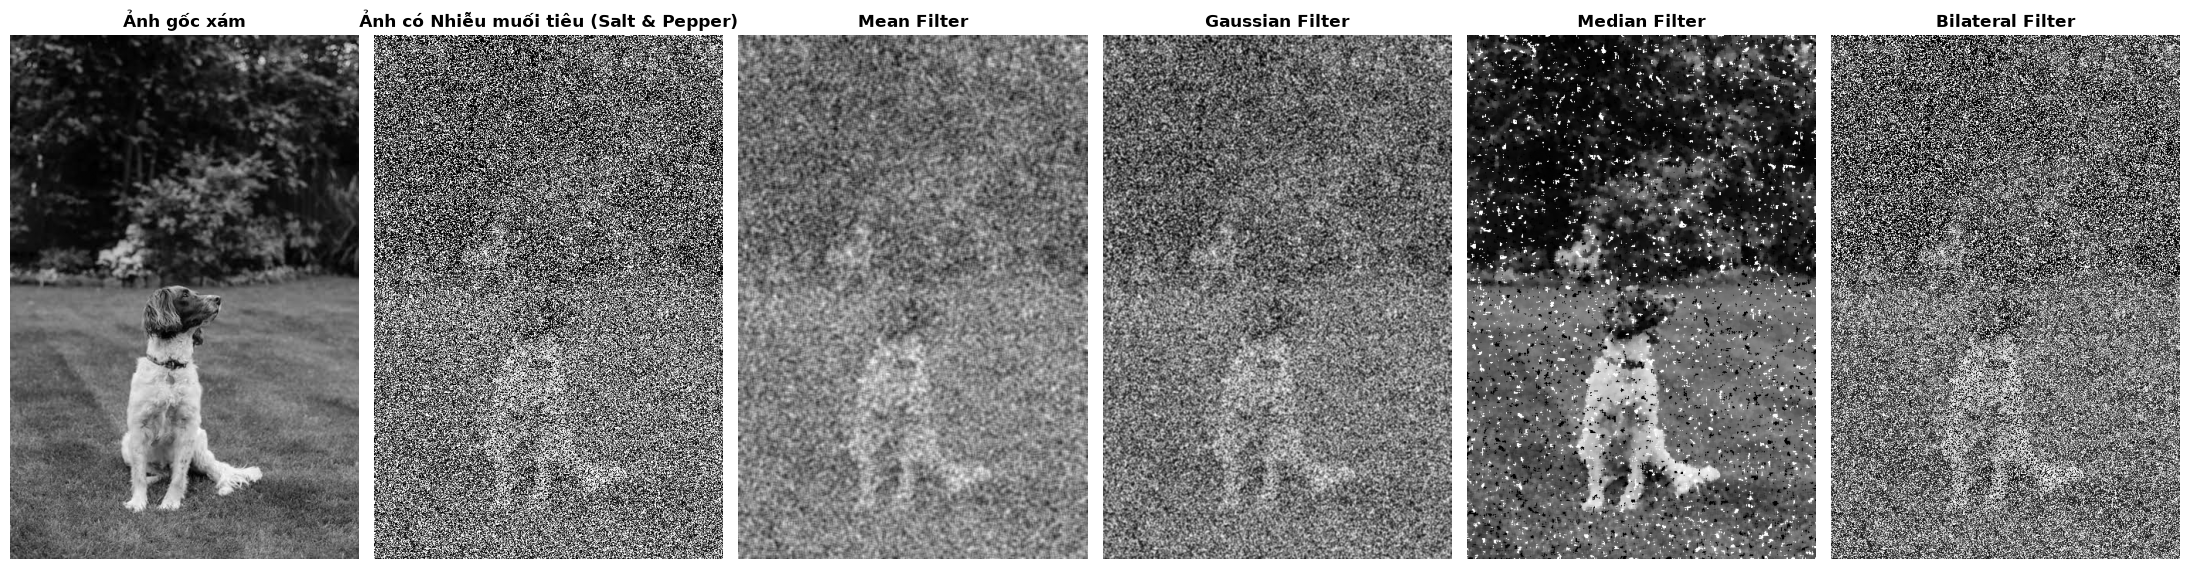

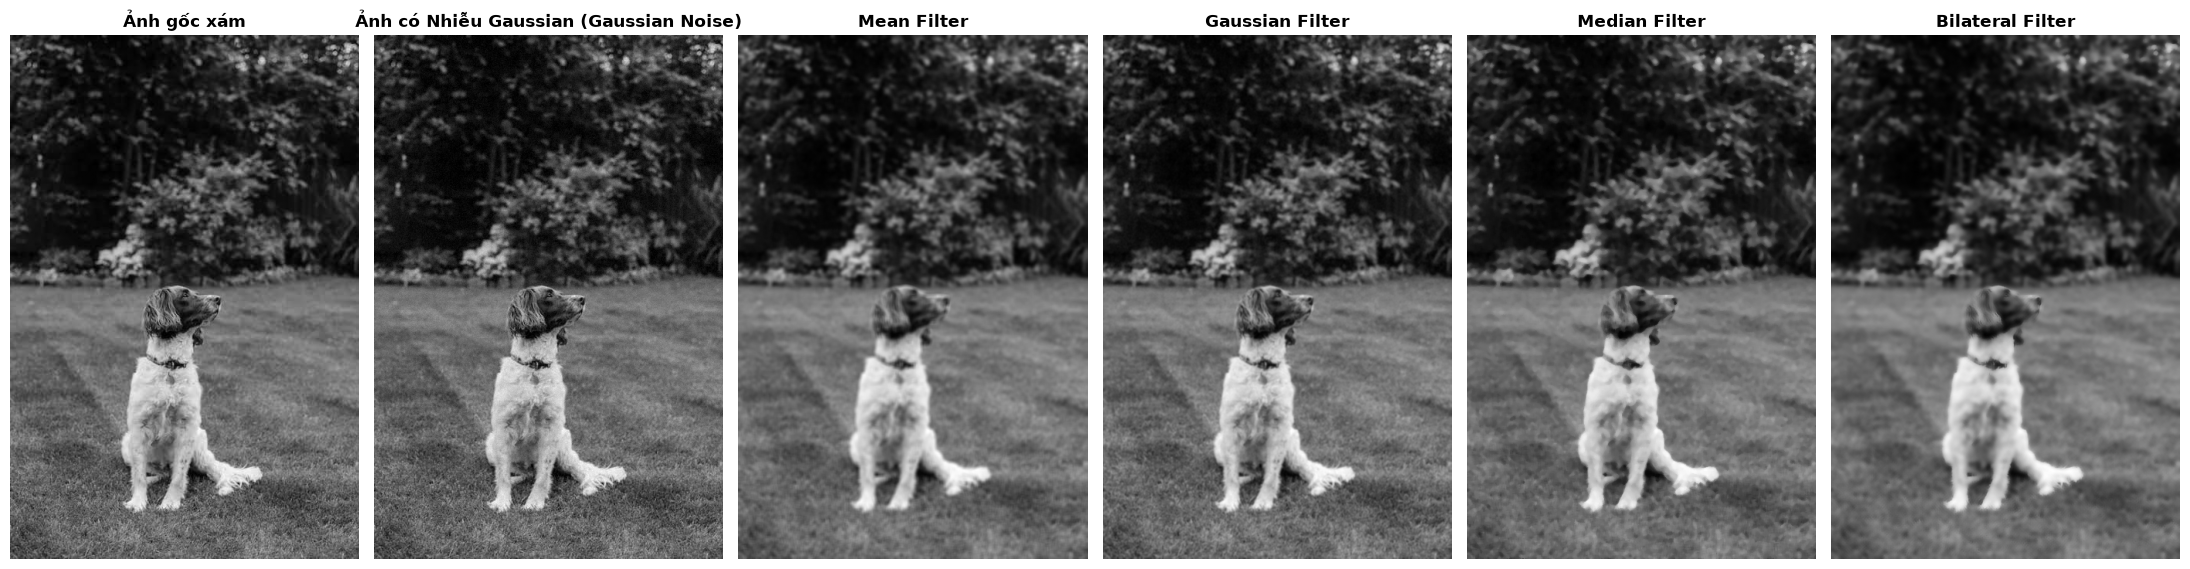

In [ ]:
def addGaussianNoise(img, mean=0, var=25):
    """
    Thêm nhiễu Gauss (Additive Gaussian Noise) vào ảnh.
    
    Args:
        img (np.ndarray): Ảnh đầu vào.
        mean (float): Giá trị trung bình của nhiễu.
        var (float): Phương sai (variance) của nhiễu.
    Returns:
        np.ndarray: Ảnh sau khi đã được gán nhiễu.
    """
    sigma = var ** 0.5
    gaussian_noise = np.random.normal(mean, sigma, img.shape)
    imgNoisy = img.astype(np.float32) + gaussian_noise
    # Giới hạn giá trị pixel trong khoảng [0, 255] và chuyển về uint8
    imgNoisy = np.clip(imgNoisy, 0, 255).astype(np.uint8)
    return imgNoisy

def addSaltNoise(img, ratio = 0.01):
    """
        Thêm nhiễu muối tiêu (Salt-and-Pepper Noise) vào ảnh với tỷ lệ tùy chỉnh.
        
        Args:
            img (np.ndarray): Ảnh đầu vào.
            ratio (float): Tỷ lệ pixel bị nhiễu so với tổng số pixel (mặc định là 0.01 tương đương 1%).
                           Ví dụ: 0.02 là 2%, 0.05 là 5%.
            
        Returns:
            np.ndarray: Ảnh sau khi đã được gán nhiễu.
    """
    # Tính số lượng điểm nhiễu dựa trên tổng số pixel
    numNoise = int(img.size * ratio)
    imgNoisy = img.copy()

    # Thêm ngẫu nhiên các điểm nhiễu trắng (255) hoặc đen (0)
    for _ in range(numNoise):
        yCoord = np.random.randint(0, img.shape[0])
        xCoord = np.random.randint(0, img.shape[1])
        imgNoisy[yCoord, xCoord] = 255 if np.random.rand() > 0.5 else 0

    return imgNoisy
    
def compareFilter(img, typeNoise="salt"):
    """
    So sánh trực quan 4 bộ lọc không gian trên ảnh bị gán nhiễu nhân tạo.
    
    Args:
        img (np.ndarray): Ảnh đầu vào (khuyến nghị ảnh xám 2D).
        typeNoise (str): Loại nhiễu ("salt" hoặc "gaussian").
    """
    # Tạo nhiễu tương ứng dựa theo loại người dùng yêu cầu
    if typeNoise.lower() == "salt":
        imgNoisy = addSaltNoise(img)
        noise_name = "Nhiễu muối tiêu (Salt & Pepper)"
    else:
        imgNoisy = addGaussianNoise(img, mean=0, var=25)
        noise_name = "Nhiễu Gaussian (Gaussian Noise)"
        
    # Thực thi 4 loại lọc trên cùng một ảnh có nhiễu
    images_list = [
        img,
        imgNoisy,                                      
        cv2.blur(imgNoisy, (5, 5)),
        cv2.GaussianBlur(imgNoisy, (5, 5), 0.85),
        cv2.medianBlur(imgNoisy, 5),
        cv2.bilateralFilter(imgNoisy, 9, 75, 75)
    ]

    titles_list = [
        "Ảnh gốc xám",
        f"Ảnh có {noise_name}",
        "Mean Filter",
        "Gaussian Filter",
        "Median Filter",
        "Bilateral Filter"
    ]

    # Hiển thị trực quan (Kiểm tra lại tên tham số force_gray / forceGray khớp với hàm gốc của em)
    displayIMG(titles_list, images_list, 22, 6, forceGray=True)

# --- Khối thực thi khảo sát ---
# 1. Khảo sát hiệu quả dưới tác động của Nhiễu muối tiêu
compareFilter(imgGray, typeNoise="salt")

# 2. Khảo sát hiệu quả dưới tác động của Nhiễu Gauss
compareFilter(imgGray, typeNoise="gaussian")